# Розвідувальний аналіз даних (EDA): ціноутворення на ноутбуки

**Мета:** з'ясувати, які характеристики ноутбука найсильніше впливають на ціну,
і обґрунтувати вибір ознак та типу цільової змінної для моделі прогнозування.

**Джерело даних:** таблиця `laptops_clean` (PostgreSQL), результат ETL-пайплайну.

**1. Загальний огляд данних**

In [1]:
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / "docker-compose.yml").exists())

df = pl.read_parquet(REPO_ROOT / "data" / "processed" / "feature_set.parquet")
pdf = df.to_pandas()          
sns.set_theme(style="whitegrid")


In [2]:
df.shape

(1216, 21)

In [3]:
df.schema

Schema([('raw_id', Int64),
        ('company', Categorical),
        ('type_name',
         Enum(categories=['Notebook', 'Ultrabook', 'Gaming', '2 in 1 Convertible', 'Workstation', 'Netbook', 'Unknown'])),
        ('inches', Float32),
        ('ram', String),
        ('opSys',
         Enum(categories=['Windows 10', 'Windows 10 S', 'Windows 7', 'Linux', 'macOS', 'Mac OS X', 'Chrome OS', 'No Os', 'Unknown'])),
        ('weight', Float64),
        ('price', Decimal(precision=38, scale=4)),
        ('ram_gb', Int32),
        ('screen_width', Int32),
        ('screen_height', Int32),
        ('is_ips', Boolean),
        ('is_touchscreen', Boolean),
        ('cpu_brand', Enum(categories=['Intel', 'AMD', 'Unknown'])),
        ('cpu_model', String),
        ('cpu_ghz', Float32),
        ('storage_gb', Float64),
        ('storage_type', String),
        ('gpu_brand', Enum(categories=['Nvidia', 'AMD', 'Intel', 'Unknown'])),
        ('gpu_model', String),
        ('cpu_gpu_pair', String)])

In [4]:
df.describe()

statistic,raw_id,company,type_name,inches,ram,opSys,weight,price,ram_gb,screen_width,screen_height,is_ips,is_touchscreen,cpu_brand,cpu_model,cpu_ghz,storage_gb,storage_type,gpu_brand,gpu_model,cpu_gpu_pair
str,f64,str,str,f64,str,str,f64,f64,f64,f64,f64,f64,f64,str,str,f64,f64,str,str,str,str
"""count""",1216.0,"""1216""","""1216""",1215.0,"""1216""","""1216""",1216.0,1216.0,1216.0,1216.0,1216.0,1216.0,1216.0,"""1216""","""1215""",1215.0,1215.0,"""1215""","""1216""","""1216""","""1215"""
"""null_count""",0.0,"""0""","""0""",1.0,"""0""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""0""","""1""",1.0,1.0,"""1""","""0""","""0""","""1"""
"""mean""",637.310855,null,null,15.106996,null,null,2.050288,57706.873958,8.20477,1881.404605,1063.424342,0.274671,0.146382,null,null,2.293514,437.083128,null,null,null,null
"""std""",368.84957,null,null,1.968996,null,null,0.785481,31878.4868,4.900156,461.803693,266.710955,null,null,null,null,0.503153,357.125849,null,null,null,null
"""min""",1.0,null,null,10.1,"""12GB""",null,0.0002,9270.72,1.0,1366.0,768.0,0.0,0.0,null,"""A10-Series 9600P""",0.9,8.0,"""Flash Storage""",null,"""FirePro W4190M""","""A10-Series 9600P | Radeon R5 4…"
"""25%""",320.0,null,null,14.0,null,null,1.5,31914.72,4.0,1600.0,900.0,null,null,null,null,2.0,256.0,null,null,null,null
"""50%""",635.0,null,null,15.6,null,null,2.04,52054.56,8.0,1920.0,1080.0,null,null,null,null,2.5,256.0,null,null,null,null
"""75%""",958.0,null,null,15.6,null,null,2.3,77250.672,8.0,1920.0,1080.0,null,null,null,null,2.7,512.0,null,null,null,null
"""max""",1274.0,null,null,35.599998,"""8GB""",null,11.1,149916.6,64.0,3840.0,2160.0,1.0,1.0,null,"""Xeon E3-1505M V6""",3.6,2000.0,"""SSD""",null,"""UHD Graphics 620""","""Xeon E3-1505M V6 | Quadro M620"""


In [5]:
df.null_count()

raw_id,company,type_name,inches,ram,opSys,weight,price,ram_gb,screen_width,screen_height,is_ips,is_touchscreen,cpu_brand,cpu_model,cpu_ghz,storage_gb,storage_type,gpu_brand,gpu_model,cpu_gpu_pair
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,1,1,1,0,0,1


**Висновки:** Після очистки, нормалізації та порсингу усіх ознак данних із таблиці сирих данних raw_laptops кількість рядків зменшилася
на 86 (базово - 1302), при цьому кількість окремо виділених ознак у вихідній таблиці laptops_clean зрозсла на 8 (базово - 12).
    Ознаки з текстовим типом данних були нормалізовані до категоріального типу, числові ознаки відокремлені від текстових фрагментів та 
приведені до відповідних таблиці типів (integer, numeric)
    Ознаки що відображають наявність/відсутність певної особливості приведені до логічного типу boolean

**2. Розподіл цільової змінної**

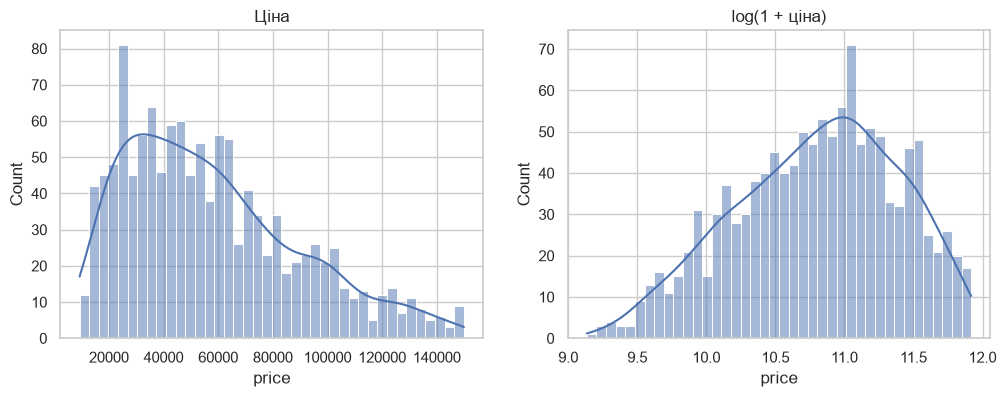

In [6]:
import numpy as np
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(pdf["price"], bins=40, kde=True, ax=ax[0]); ax[0].set_title("Ціна")
price_numeric = pdf["price"].astype(float)
sns.histplot(np.log1p(price_numeric), bins=40, kde=True, ax=ax[1]); ax[1].set_title("log(1 + ціна)")
plt.savefig(REPO_ROOT / "docs" / "analytics_graphs" / "eda_distribution_of_the_target_variable(price).png", dpi=150, bbox_inches="tight")

**Висновки:** З наведених графіків видно, що ціна має правий "хвіст", а після логарифмування розподіл ближчий до нормального. Це пряме обґрунтування використання TransformedTargetRegressor з log1p у train.py

**3. Кореляційна матриця**


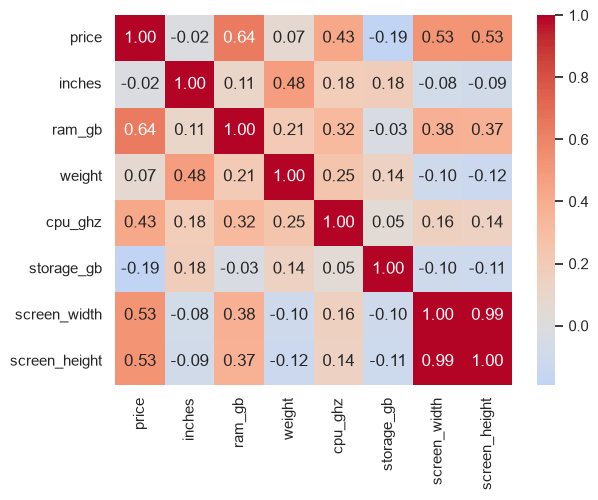

In [7]:
num_cols = ["price", "inches", "ram_gb", "weight", "cpu_ghz",
            "storage_gb", "screen_width", "screen_height"]
sns.heatmap(pdf[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.savefig(REPO_ROOT / "docs" / "analytics_graphs" /"eda_features_matrix_correlation.png", dpi=150, bbox_inches="tight")


**Висновки:** Найсильніше з ціною корелює RAM (r = 0.64): це єдина ознака із помітним лінійним зв'язком. Далі йдуть роздільна здатність екрана (screen_width і screen_height, обидві r = 0.53), частота процесора (r = 0.43) та обсяг накопичувача (r = 0.36). Діагональ (r = −0.02) і вага (r = 0.07) практично не мають лінійного зв'язку з ціною. Жодна ознака не корелює з ціною аномально сильно (r > 0.9), тому підозри на витік цільової змінної немає.

Мультиколінеарність. screen_width і screen_height майже ідентичні (r = 0.99): це одна й та сама інформація (роздільна здатність), записана двома колонками. Помітний також зв'язок між inches і weight (r = 0.48): більші ноутбуки логічно важчі. Решта пар ознак корелюють слабко або помірно (r < 0.4), тобто інформація в них здебільшого різна.

Обмеження. Коефіцієнт Пірсона фіксує лише лінійні залежності й не бачить категоріальних ознак (бренд, тип ноутбука, ОС, тип накопичувача). Низька кореляція storage_gb пояснюється тим, що великий обсяг часто означає дешевий HDD, а менший SSD коштує дорожче; це видно лише разом із storage_type. Слабкий зв'язок inches і weight з ціною не означає, що вони марні для моделі: вони можуть працювати у взаємодії з іншими ознаками, а їхній реальний внесок покаже feature importance.

**4. Числові ознаки і ціна**


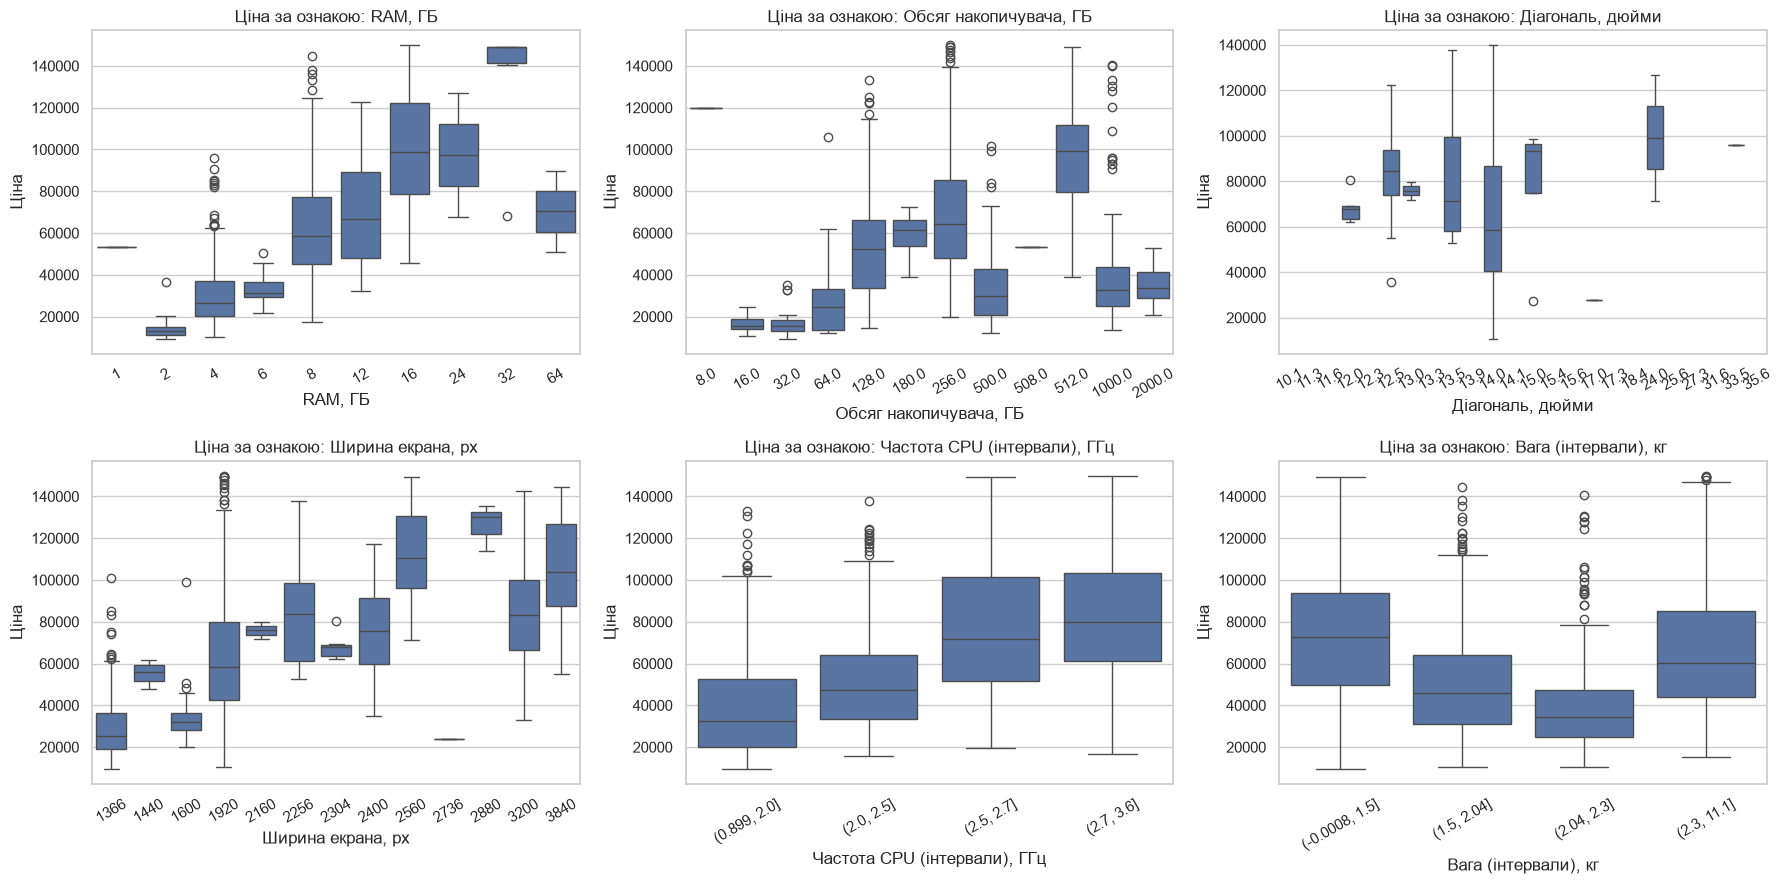

ram_gb
1       53226.72
2       13160.16
4      26557.416
6     31343.8248
8       58767.84
12      66546.72
16      98674.56
24      97262.64
32     149130.72
64    70373.2896
Name: price, dtype: object
storage_gb
8.0       119826.72
16.0      15528.456
32.0       15397.92
64.0       24721.92
128.0      52587.36
180.0      61218.72
256.0       64202.4
500.0      29783.52
508.0      53386.56
512.0       99100.8
1000.0     32820.48
2000.0     33513.12
Name: price, dtype: object


In [8]:
import pandas as pd

fig, axes = plt.subplots(2, 3, figsize=(18, 9))

sns.boxplot(data=pdf, x="ram_gb", y="price", ax=axes[0, 0])
sns.boxplot(data=pdf, x="storage_gb", y="price", ax=axes[0, 1])
sns.boxplot(data=pdf, x="inches", y="price", ax=axes[0, 2])
sns.boxplot(data=pdf, x="screen_width", y="price", ax=axes[1, 0])

# неперервні ознаки розбиваємо на 4 квантильні інтервали
for ax, col in [(axes[1, 1], "cpu_ghz"), (axes[1, 2], "weight_kg")]:
    col_name = "weight" if col == "weight_kg" else col
    bins = pd.qcut(pdf[col_name], q=4, duplicates="drop")
    sns.boxplot(x=bins, y=pdf["price"], ax=ax)

titles = ["RAM, ГБ", "Обсяг накопичувача, ГБ", "Діагональ, дюйми",
          "Ширина екрана, px", "Частота CPU (інтервали), ГГц", "Вага (інтервали), кг"]
for ax, t in zip(axes.flat, titles):
    ax.set_title(f"Ціна за ознакою: {t}")
    ax.set_xlabel(t); ax.set_ylabel("Ціна")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.savefig(REPO_ROOT / "docs" / "analytics_graphs" /"eda_numeric_boxplots.png", dpi=150, bbox_inches="tight")
plt.show()

print(pdf.groupby("ram_gb")["price"].median())
print(pdf.groupby("storage_gb")["price"].median())


**Висновки:** RAM показує найчіткішу монотонну залежність: медіанна ціна послідовно зростає від 4 до 16–32 ГБ (з [..] до [..]), а розкид у межах групи порівняно малий. Це найсильніша числова ознака.
Обсяг накопичувача також пов'язаний із ціною, але нерівномірно: великі обсяги часто належать дешевим HDD, а 128–512 ГБ SSD дорожчі за 1 ТБ HDD. Отже, storage_gb має сенс лише разом із storage_type.
Ширина екрана: ноутбуки з високою роздільністю (3200–3840 px) помітно дорожчі, а різниця між HD і Full HD менша.
CPU (ГГц) дає помірний, зашумлений ефект: частота не враховує покоління й клас процесора, тому її роль слабша, ніж у RAM.
Діагональ і вага не мають монотонної залежності: легкі ультрабуки та важкі ігрові моделі обидва можуть бути дорогими. Лінійно ці ознаки ціну не пояснюють, і для лінійної регресії від них не варто чекати багато.
У всіх групах є викиди зверху: це преміальні моделі, і вони природні для цільової змінної з правим "хвостом".

**5. Категоріальні ознаки і ціна**

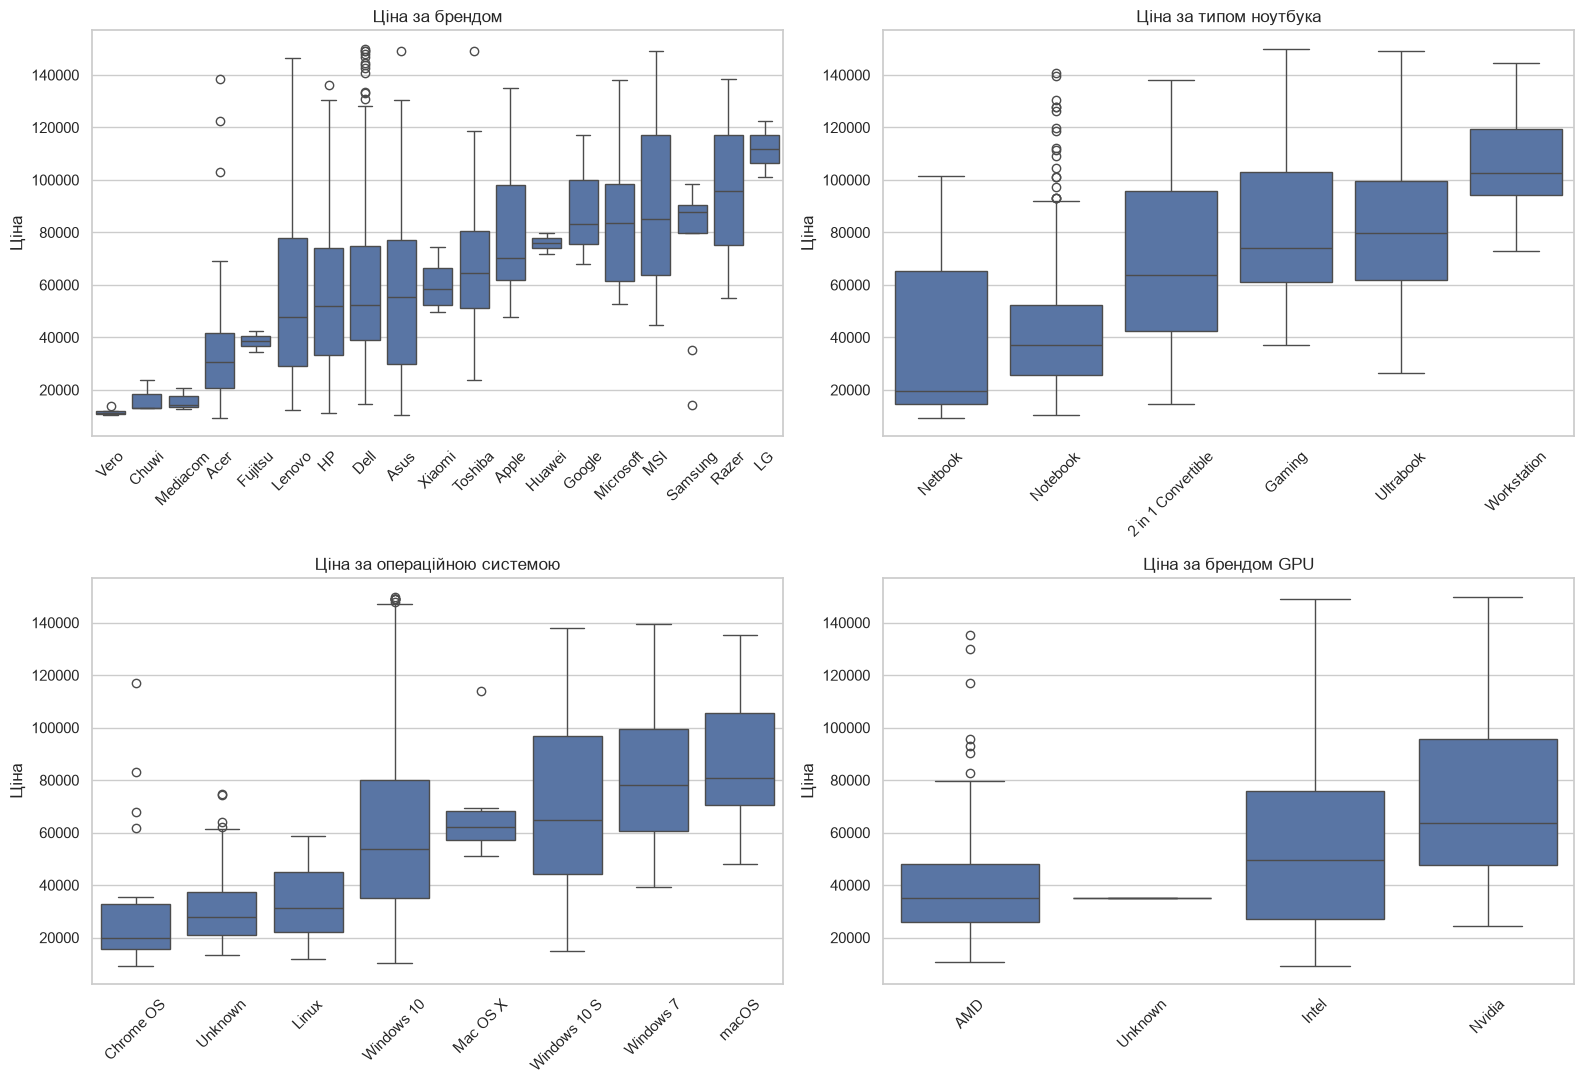

company
Lenovo       277
Dell         271
HP           256
Asus         145
Acer         101
MSI           53
Toshiba       47
Apple         20
Samsung        9
Mediacom       7
Microsoft      6
Vero           4
Xiaomi         4
Google         3
Razer          3
Chuwi          3
LG             3
Fujitsu        2
Huawei         2
Name: count, dtype: int64 

type_name
Notebook              686
Ultrabook             187
Gaming                186
2 in 1 Convertible    112
Workstation            23
Netbook                22
Name: count, dtype: int64 

opSys
Windows 10      999
Unknown          64
Linux            57
Windows 7        41
Chrome OS        27
macOS            12
Windows 10 S      8
Mac OS X          8
No Os             0
Name: count, dtype: int64 

gpu_brand
Intel      683
Nvidia     364
AMD        168
Unknown      1
Name: count, dtype: int64 

cpu_brand
Intel      1155
AMD          60
Unknown       1
Name: count, dtype: int64 



In [9]:
for c in ["company", "type_name", "opsys", "cpu_brand", "gpu_brand", "storage_type"]:
    if c in pdf.columns:
        pdf[c] = pdf[c].astype(str)

def boxplot_by(ax, col, title):
    order = pdf.groupby(col)["price"].median().sort_values().index
    sns.boxplot(data=pdf, x=col, y="price", order=order, ax=ax)
    ax.set_title(title); ax.set_xlabel(""); ax.set_ylabel("Ціна")
    ax.tick_params(axis="x", rotation=45)

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
boxplot_by(axes[0, 0], "company", "Ціна за брендом")
boxplot_by(axes[0, 1], "type_name", "Ціна за типом ноутбука")
boxplot_by(axes[1, 0], "opSys", "Ціна за операційною системою")
boxplot_by(axes[1, 1], "gpu_brand", "Ціна за брендом GPU")

plt.tight_layout()
plt.savefig(REPO_ROOT / "docs" / "analytics_graphs" /"eda_categorial.png", dpi=150, bbox_inches="tight")
plt.show()

for col in ["company", "type_name", "opSys", "gpu_brand", "cpu_brand"]:
    print(pdf[col].value_counts(), "\n")

**Висновки:** Тип ноутбука сильно впливає на ціну: Gaming і Workstation мають найвищі медіани, Netbook і Notebook найнижчі, Ultrabook посередині.
Бренд розділяє ринок на сегменти: [Razer/Apple/MSI] зазвичай на верхніх позиціях, [Acer/Chuwi/Vero] на нижніх. Але частина брендів має лише кілька ноутбуків (див. value_counts), тому їх медіани статистично ненадійні.
ОС: macOS і Windows 10 помітно дорожчі за “No OS”/Linux, але ця ознака значною мірою корелює з брендом (macOS це лише Apple), і дублювання інформації для дерев не страшне.
GPU: Nvidia асоціюється з дорожчими (ігровими) моделями, Intel із бюджетними. Ознака несе сигнал, але частково дублює type_name.
Практичний наслідок: рідкісні категорії бренду варто згрупувати в Other (наприклад, бренди, що трапляються менше 10 разів), інакше one-hot додасть багато майже порожніх колонок, а модель перенавчиться на них.

**6. Булеві ознаки**

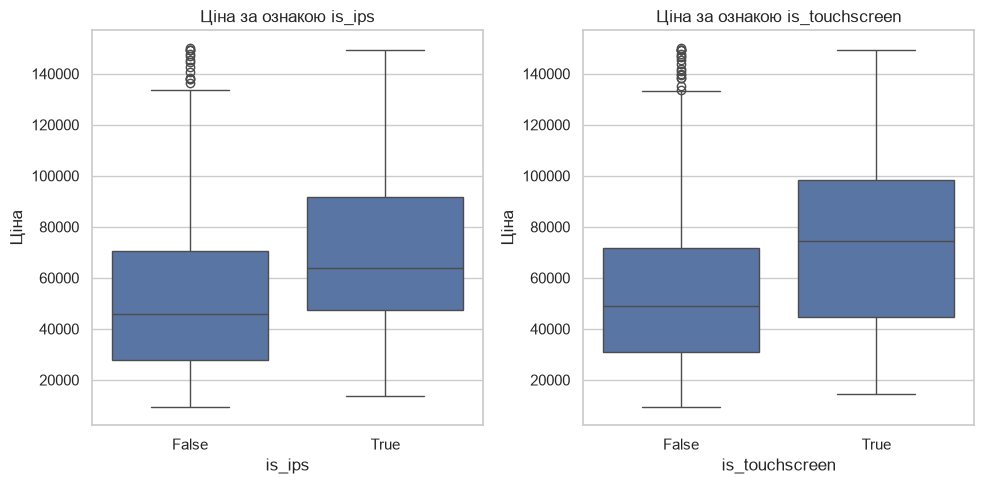

        count    median
is_ips                 
False     882  45660.96
True      334  63882.72 

                count    median
is_touchscreen                 
False            1038  49070.88
True              178  74538.72 



In [10]:
bool_cols = [c for c in ["is_ips", "is_touchscreen"] if c in pdf.columns]

fig, axes = plt.subplots(1, len(bool_cols), figsize=(5 * len(bool_cols), 5))
axes = np.atleast_1d(axes)
for ax, col in zip(axes, bool_cols):
    sns.boxplot(data=pdf, x=col, y="price", ax=ax)
    ax.set_title(f"Ціна за ознакою {col}")
    ax.set_xlabel(col); ax.set_ylabel("Ціна")

plt.tight_layout()
plt.savefig(REPO_ROOT / "docs" / "analytics_graphs" / "eda_bool_boxplots.png", dpi=150, bbox_inches="tight")
plt.show()

for col in bool_cols:
    print(pdf.groupby(col)["price"].agg(["count", "median"]), "\n")

**Висновки:** PS-матриця і сенсорний екран пов'язані з вищою медіанною ціною (різниця [..] проти [..]), але ефект частково пояснюється тим, що ці опції трапляються в дорожчих класах (Ultrabook, 2 in 1)

------------------------------------------------------------------------------------------------------------------------------------------

## Висновки EDA та рішення для моделювання

**Цільова змінна.** Ціна має правий хвіст, тому модель навчається на `log1p(price)`
(через `TransformedTargetRegressor`), а прогноз повертається у вихідній шкалі.

**Найсильніші ознаки:** `ram_gb`, `type_name`, `company`, `screen_width`, `storage_gb` + `storage_type`, `gpu_brand`.

**Допоміжні ознаки:** `cpu_ghz`, `is_ips`, `is_touchscreen`, `has_dual_storage`, `opsys`.

**Слабкі/шумні ознаки:** `weight_kg`, `inches` (немонотонна залежність). Залишаться в моделі,
але очікувано дадуть малу важливість у feature importance.

**Категорії → one-hot** у `ColumnTransformer` (`company`, `type_name`, `opsys`, `cpu_brand`,
`gpu_brand`, `storage_type`) з `handle_unknown="ignore"`.

**Числові → `StandardScaler`** (потрібно лінійній регресії, деревам не шкодить).

**Не використовуємо як ознаки:** `id`, `raw_id` (службові ідентифікатори).

**Ризики:** мала вибірка (~[N] рядків) → використано крос-валідацію, а не одне
train/test розбиття; частина брендів має менше 10 прикладів.

**Очікування:** лінійна регресія на `log(price)` дає базовий рівень, ансамблеві моделі
(Random Forest, HistGradientBoosting) мають його перевершити завдяки нелінійним взаємодіям
(напр. RAM × тип ноутбука).